# 1. Import Libraries

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, precision_score, recall_score, precision_recall_curve,fbeta_score,average_precision_score,
                              f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss
import time
import scipy.sparse as sp
import optuna
import shap

import warnings
warnings.filterwarnings('ignore')


# 2. Load & Understand Dataset

In [41]:
# ── Load dataset ──────────────────────────────────────────────────
import os
full = os.path.join("data", "WA_Fn-UseC_-Telco-Customer-Churn (1).csv")
df = pd.read_csv(full )
print(f"Dataset Shape   : {df.shape}")
print(f"Total Rows      : {df.shape[0]}")
print(f"Total Columns   : {df.shape[1]}")
df.head()

Dataset Shape   : (7043, 21)
Total Rows      : 7043
Total Columns   : 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [42]:
# ── Data types overview ───────────────────────────────────────────
print("Column Data Types:")
print(df.dtypes.value_counts())
print(f"\nNumerical columns  : {df.select_dtypes(include=[np.number]).shape[1]}")
print(f"Categorical columns: {df.select_dtypes(include=['object']).shape[1]}")

Column Data Types:
str        18
int64       2
float64     1
Name: count, dtype: int64

Numerical columns  : 3
Categorical columns: 18


In [43]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [45]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [46]:
df.duplicated().sum()

np.int64(0)

In [47]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [48]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [49]:
df.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
4982,7124-UGSUR,Female,1,Yes,No,61,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),104.40,6405,Yes
3724,5201-CBWYG,Male,0,Yes,Yes,62,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Bank transfer (automatic),24.80,1476.25,No
4923,6075-QMNRR,Female,0,No,No,52,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),49.75,2535.55,No
1181,8399-YNDCH,Male,1,No,No,21,Yes,No,DSL,No,...,Yes,No,Yes,No,Month-to-month,Yes,Bank transfer (automatic),60.05,1236.15,Yes
7032,6894-LFHLY,Male,1,No,No,1,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,75.75,75.75,Yes


In [50]:
categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns 

for col in categorical_cols:
    if df[col].nunique() >= 2:
        print(col, ":", df[col].nunique(), "categories")

customerID : 7043 categories
gender : 2 categories
Partner : 2 categories
Dependents : 2 categories
PhoneService : 2 categories
MultipleLines : 3 categories
InternetService : 3 categories
OnlineSecurity : 3 categories
OnlineBackup : 3 categories
DeviceProtection : 3 categories
TechSupport : 3 categories
StreamingTV : 3 categories
StreamingMovies : 3 categories
Contract : 3 categories
PaperlessBilling : 2 categories
PaymentMethod : 4 categories
TotalCharges : 6531 categories
Churn : 2 categories


In [51]:
categorical_cols

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges',
       'Churn'],
      dtype='str')

# 3. Data Cleaning

In [52]:
df = df.copy()

# 1. Remove customerID because it is a unique identifier
df.drop(columns=["customerID"], errors="ignore", inplace=True)

# 2. Convert blank TotalCharges values to NaN and then to numeric
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True),
        errors="coerce"
    )

# 3. Clean the target column while preserving missing values
df["Churn"] = df["Churn"].astype("string").str.strip()

# 4. Remove rows with missing target values
df = df.dropna(subset=["Churn"]).copy()

# 5. Keep only valid target labels
df = df[df["Churn"].isin(["Yes", "No"])].copy()

# 6. Check the results
print("Shape after basic cleaning:", df.shape)
print("\nChurn values:")
print(df["Churn"].value_counts())

print("\nMissing values after cleaning:")
display(df.isna().sum().sort_values(ascending=False).head(15))

Shape after basic cleaning: (7043, 20)

Churn values:
Churn
No     5174
Yes    1869
Name: count, dtype: Int64

Missing values after cleaning:


TotalCharges        11
gender               0
Partner              0
SeniorCitizen        0
Dependents           0
tenure               0
MultipleLines        0
PhoneService         0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
InternetService      0
TechSupport          0
StreamingTV          0
Contract             0
dtype: int64

In [53]:
print(df["Churn"].unique())
print(df["Churn"].value_counts(dropna=False))

<StringArray>
['No', 'Yes']
Length: 2, dtype: string
Churn
No     5174
Yes    1869
Name: count, dtype: Int64


# 4. Exploratory Data Analysis (EDA)

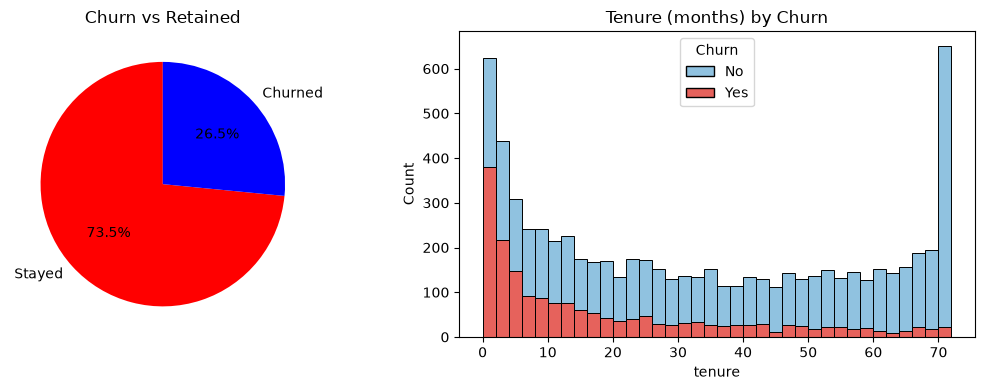

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].pie(df['Churn'].value_counts().sort_index(), labels=['Stayed', 'Churned'], autopct='%1.1f%%',
            colors=['red', 'blue'], startangle=90)
axes[0].set_title('Churn vs Retained')
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=36, ax=axes[1], palette=['#6baed6', '#de2d26'])
axes[1].set_title('Tenure (months) by Churn')
plt.tight_layout(); plt.show()

The dataset is imbalanced — roughly a quarter of customers churned. This is factored into model training (class weighting) and threshold selection later on.

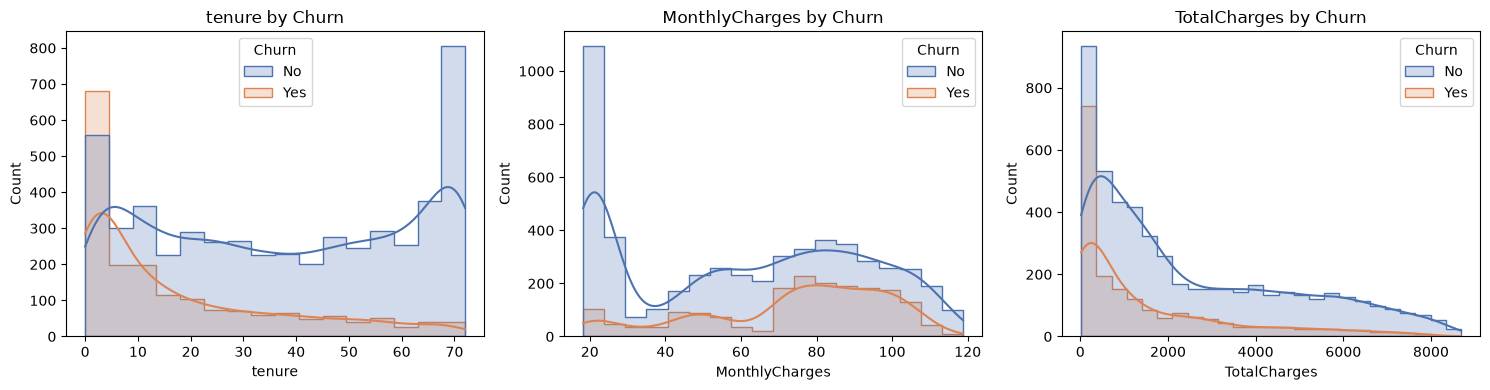

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    data = df.copy()
    data[col] = pd.to_numeric(data[col], errors='coerce')
    sns.histplot(data=data, x=col, hue='Churn', kde=True, element='step', ax=ax, palette=['#4C72B0', '#DD8452'])
    ax.set_title(f'{col} by Churn')
plt.tight_layout()
plt.show()

- **Tenure:** churners are concentrated in the first few months — new customers are the highest-risk group.
- **MonthlyCharges:** churners skew toward higher monthly bills.
- **TotalCharges:** correlates with tenure, so churners cluster at low total spend (short tenure).

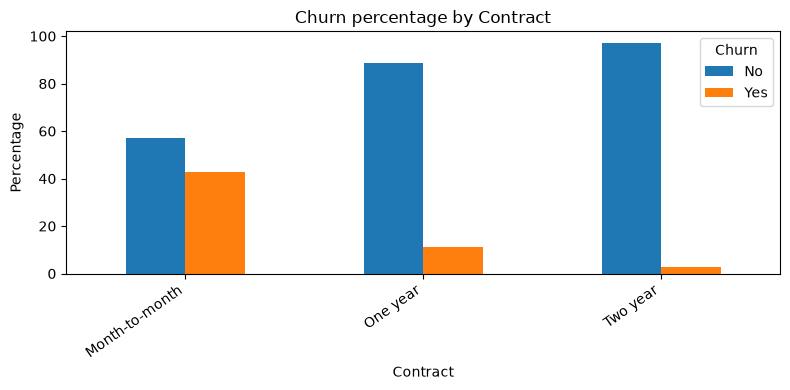

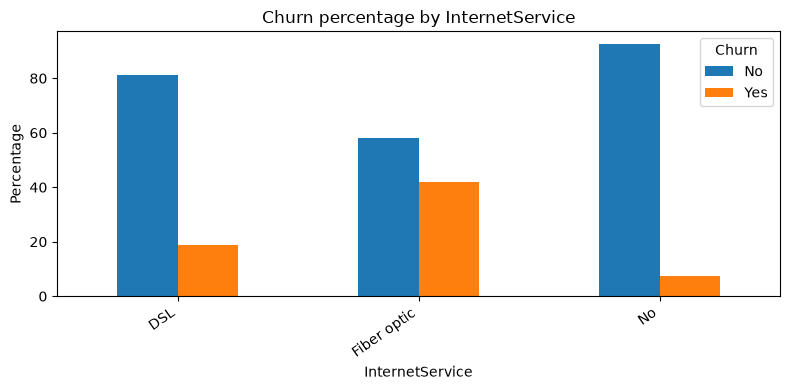

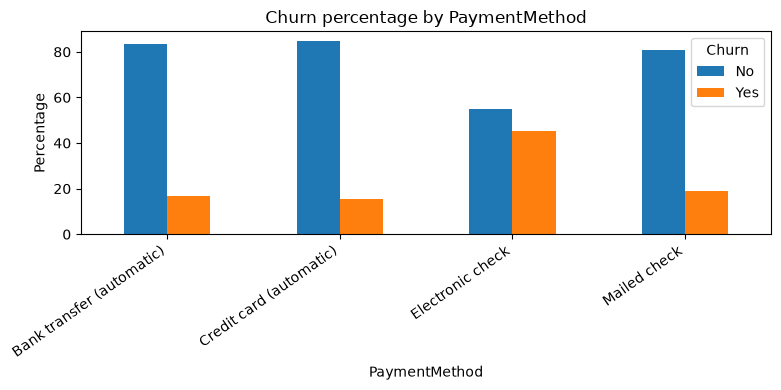

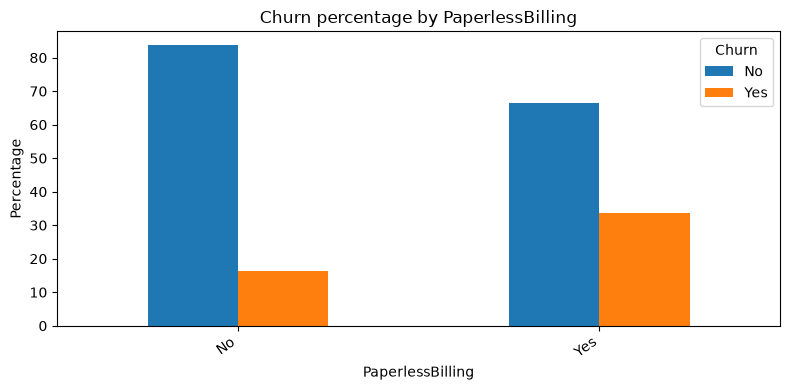

In [56]:
# Churn rate by selected categorical variables
categorical_to_plot = [
    col for col in ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling"]
    if col in df.columns
]

for col in categorical_to_plot:
    churn_rate = pd.crosstab(df[col], df["Churn"], normalize="index") * 100
    ax = churn_rate.plot(kind="bar", figsize=(8, 4))
    ax.set_title(f"Churn percentage by {col}")
    ax.set_ylabel("Percentage")
    ax.set_xlabel(col)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

### Correlation with churn

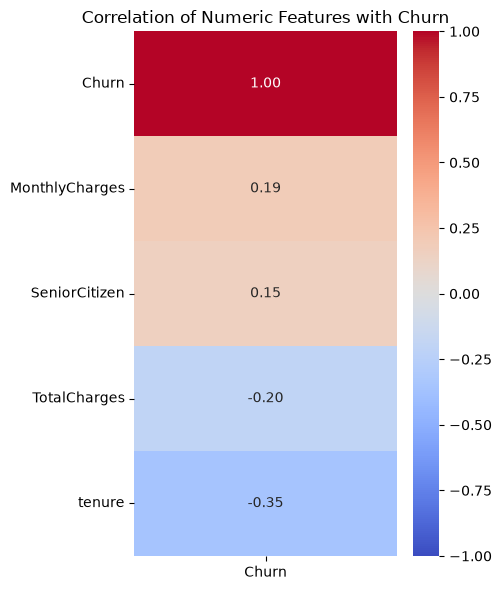

Top positive correlations:


,Churn
MonthlyCharges,0.193356
SeniorCitizen,0.150889
TotalCharges,-0.199484
tenure,-0.352229



Top negative correlations:


,Churn
tenure,-0.352229
TotalCharges,-0.199484
SeniorCitizen,0.150889
MonthlyCharges,0.193356


In [57]:
# Create a numeric target for correlation without overwriting df["Churn"].
churn_numeric = df["Churn"].astype("string").str.strip().map({"No": 0, "Yes": 1})

if churn_numeric.isna().any():
    raise ValueError(
        "Churn contains missing or unexpected labels. "
        f"Observed values: {df['Churn'].value_counts(dropna=False).to_dict()}"
    )

numeric_df = df.select_dtypes(include=np.number).drop(columns=["Churn"], errors="ignore").copy()
numeric_df["Churn"] = churn_numeric.astype(int)

corr_matrix = numeric_df.corr()
churn_corr = corr_matrix[["Churn"]].sort_values(by="Churn", ascending=False)

plt.figure(figsize=(5, max(6, 0.45 * len(churn_corr))))
sns.heatmap(churn_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation of Numeric Features with Churn")
plt.tight_layout()
plt.show()

print("Top positive correlations:")
display(churn_corr.drop(index="Churn").head(6))
print("\nTop negative correlations:")
display(churn_corr.drop(index="Churn").tail(6).sort_values("Churn"))

# 5. Train/Test Split & Preprocessing

In [58]:
X = df.drop(columns=['Churn'])
y = df['Churn'].map({"No": 0, "Yes": 1})
if y.isna().any():
    raise ValueError("Expected target values 'Yes' and 'No' in the Churn column.")


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}  churn rate {y_train.mean()*100:.2f}%")
print(f"Test : {X_test.shape}  churn rate {y_test.mean()*100:.2f}%")

Train: (5634, 19)  churn rate 26.54%
Test : (1409, 19)  churn rate 26.54%


In [59]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical feature count:", len(categorical_features))

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical feature count: 15


In [60]:
def build_preprocessor():
    return clone(preprocessor)   # fresh, unfitted copy for every model

def build_model(clf):
    """Preprocessing + classifier as ONE estimator."""
    return Pipeline([('prep', build_preprocessor()), ('clf', clf)])

### 5.1 Multicollinearity check (VIF)
*VIF is an optional diagnostic for multicollinearity, not a requirement for tree-based models.*

In [61]:

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


X_vif = X_train.drop(columns=["customerID"], errors="ignore").copy()
if "TotalCharges" in X_vif.columns:
    X_vif["TotalCharges"] = pd.to_numeric(X_vif["TotalCharges"], errors="coerce")

X_vif = pd.get_dummies(X_vif, drop_first=True, dtype=float)
X_vif = X_vif.replace([np.inf, -np.inf], np.nan)
X_vif = X_vif.fillna(X_vif.median(numeric_only=True))
X_vif = X_vif.dropna(axis=1, how="all")
X_vif = X_vif.loc[:, X_vif.nunique(dropna=True) > 1]

if X_vif.shape[1] < 2:
    print("Not enough non-constant features to calculate VIF.")
else:
    X_vif_const = add_constant(X_vif, has_constant="add")
    vif_data = pd.DataFrame({
        "Feature": X_vif_const.columns,
        "VIF": [
            variance_inflation_factor(X_vif_const.to_numpy(), i)
            for i in range(X_vif_const.shape[1])
        ]
    })
    vif_data = vif_data[vif_data["Feature"] != "const"].sort_values("VIF", ascending=False)
    display(vif_data.head(15))

,Feature,VIF
9,MultipleLines_No phone service,1.000800e+15
8,PhoneService_Yes,1.000800e+15
12,InternetService_No,1.000800e+15
13,OnlineSecurity_No internet service,1.000800e+15
17,DeviceProtection_No internet service,1.000800e+15
15,OnlineBackup_No internet service,1.000800e+15
19,TechSupport_No internet service,1.000800e+15
21,StreamingTV_No internet service,1.000800e+15
23,StreamingMovies_No internet service,1.000800e+15
3,MonthlyCharges,8.618914e+02


**VIF reading:** the very large values come from structurally redundant dummies, such as `No internet service` and `No phone service`, which are fully determined by `InternetService` and `PhoneService`. `MonthlyCharges` is also high because it is largely a combination of the service columns. These features were kept, since the final models are tree-based and largely unaffected by multicollinearity; the pipeline does not rely on coefficients.

# 6. Evaluation Helpers & Baseline Models

In [62]:

BETA = 2

def get_scores(model, X):
    """Probabilities if available; otherwise raw decision scores (NOT probabilities)."""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1], True
    if hasattr(model, 'decision_function'):
        return model.decision_function(X), False
    return model.predict(X).astype(float), False

def evaluate_model(model, X_test, y_test, thresh=0.5, show_plots=True, title=''):
    y_test = np.asarray(y_test)
    scores, is_proba = get_scores(model, X_test)
    if not is_proba and thresh == 0.5:
        thresh = 0.0                      # decision_function boundary is 0, not 0.5
    pred = (scores >= thresh).astype(int)
    ap, roc = average_precision_score(y_test, scores), roc_auc_score(y_test, scores)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    print(f"Classification report (threshold={thresh:.3f}):")
    print(classification_report(y_test, pred, digits=3, zero_division=0))
    print(f"PR-AUC: {ap:.4f} | ROC-AUC: {roc:.4f} | Flagged: {pred.mean()*100:.1f}%")
    print("Confusion matrix:\n", cm)
    if show_plots:
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        p, r, _ = precision_recall_curve(y_test, scores)
        axes[0].plot(r, p)
        axes[0].axhline(y_test.mean(), color='grey', ls='--', label='no-skill')
        axes[0].scatter(recall_score(y_test, pred, zero_division=0),
                        precision_score(y_test, pred, zero_division=0),
                        color='red', zorder=3, label='chosen threshold')
        axes[0].set(xlabel='Recall', ylabel='Precision', title=f'{title} PR curve (AP={ap:.3f})')
        axes[0].legend()
        ConfusionMatrixDisplay(cm, display_labels=['Stayed', 'Churned']).plot(
            ax=axes[1], cmap='Blues', colorbar=False)
        axes[1].set_title(f'{title} Confusion matrix')
        plt.tight_layout(); plt.show()
    return {'ap': ap, 'roc': roc, 'scores': scores, 'y_pred': pred, 'cm': cm}

def pick_threshold(y_true, proba, beta=BETA):
    """Threshold maximizing F-beta. Use out-of-fold predictions from the TRAIN set."""
    prec, rec, thr = precision_recall_curve(np.asarray(y_true), proba)
    prec, rec = prec[:-1], rec[:-1]
    fb = (1 + beta**2) * prec * rec / (beta**2 * prec + rec + 1e-12)
    i = np.nanargmax(fb)
    return float(thr[i]), float(fb[i])

def threshold_analysis(y_true, proba, title='', beta=BETA,
                       thresholds=(0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6,0.7), plot=True):
    """Precision/recall/F-scores/flagged% across thresholds; returns a DataFrame."""
    y_true, proba = np.asarray(y_true), np.asarray(proba)
    if plot:
        prec, rec, thr = precision_recall_curve(y_true, proba)
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(thr, prec[:-1], label='Precision'); ax.plot(thr, rec[:-1], label='Recall')
        ax.set(xlabel='Threshold', title=f'{title} Precision/Recall vs Threshold'); ax.legend()
        plt.tight_layout(); plt.show()
    rows = []
    for t in thresholds:
        pr = (proba >= t).astype(int)
        row = {'threshold': t,
               'precision': precision_score(y_true, pr, zero_division=0),
               'recall': recall_score(y_true, pr, zero_division=0),
               'F1': f1_score(y_true, pr, zero_division=0)}
        if beta != 1:
            row[f'F{beta:g}'] = fbeta_score(y_true, pr, beta=beta, zero_division=0)
        row['flagged_%'] = pr.mean() * 100
        rows.append(row)
    return pd.DataFrame(rows).set_index('threshold').round(3)



### 6.1 Logistic Regression (linear baseline)
A simple, interpretable model. It shows whether the tree ensembles add anything over a linear model.

LogReg CV PR-AUC : 0.6600 +/- 0.0195
LogReg CV ROC-AUC: 0.8459 +/- 0.0124
Classification report (threshold=0.500):
              precision    recall  f1-score   support

           0      0.902     0.722     0.802      1035
           1      0.504     0.783     0.614       374

    accuracy                          0.738      1409
   macro avg      0.703     0.753     0.708      1409
weighted avg      0.797     0.738     0.752      1409

PR-AUC: 0.6326 | ROC-AUC: 0.8413 | Flagged: 41.2%
Confusion matrix:
 [[747 288]
 [ 81 293]]


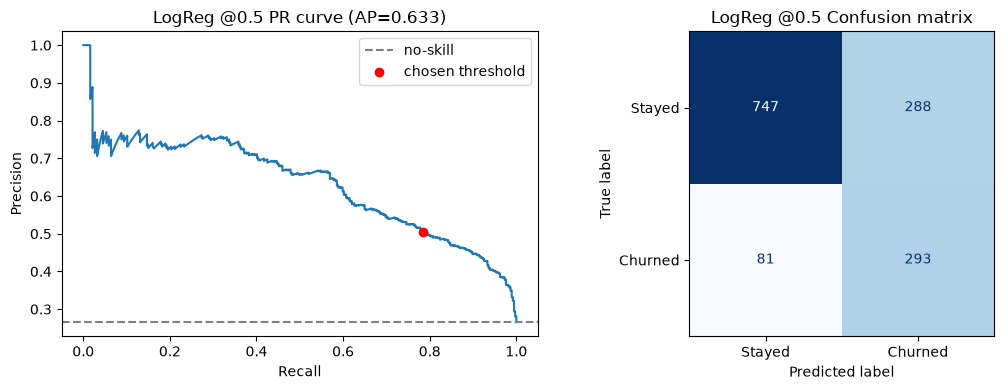

In [63]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logreg = build_model(LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42))

# 1. Cross-validated scores on the TRAINING set (same folds as the other models)
ap_lr  = cross_val_score(logreg, X_train, y_train, cv=cv, scoring='average_precision')
roc_lr = cross_val_score(logreg, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"LogReg CV PR-AUC : {ap_lr.mean():.4f} +/- {ap_lr.std():.4f}")
print(f"LogReg CV ROC-AUC: {roc_lr.mean():.4f} +/- {roc_lr.std():.4f}")

# 2. Fit on the full training set, evaluate on the test set at the default threshold
logreg.fit(X_train, y_train)
res_lr_default = evaluate_model(logreg, X_test, y_test, thresh=0.5, title='LogReg @0.5')

### 6.2 Random Forest (baseline)

RF baseline CV PR-AUC : 0.6548 +/- 0.0238
RF baseline CV ROC-AUC: 0.8453 +/- 0.0095

Best threshold: 0.309 (F2 = 0.746)


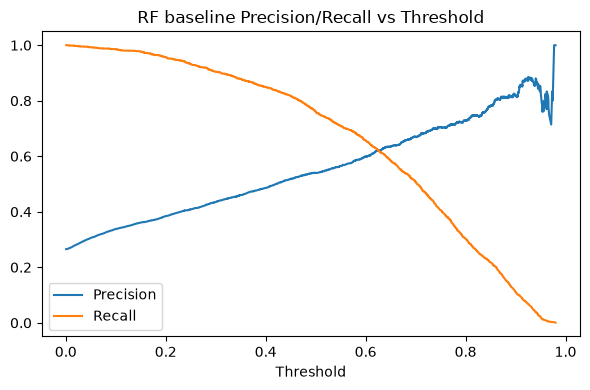

           precision  recall     F1     F2  flagged_%
threshold                                            
0.10           0.338   0.986  0.504  0.713     77.370
0.15           0.361   0.977  0.527  0.729     71.796
0.20           0.384   0.957  0.548  0.737     66.081
0.30           0.435   0.904  0.587  0.744     55.183
0.40           0.486   0.849  0.618  0.739     46.397
0.50           0.540   0.761  0.632  0.704     37.398
0.60           0.598   0.657  0.626  0.644     29.127
0.70           0.669   0.506  0.577  0.532     20.075

--- Default threshold 0.5 ---
Classification report (threshold=0.500):
              precision    recall  f1-score   support

           0      0.902     0.757     0.824      1035
           1      0.535     0.773     0.632       374

    accuracy                          0.762      1409
   macro avg      0.719     0.765     0.728      1409
weighted avg      0.805     0.762     0.773      1409

PR-AUC: 0.6444 | ROC-AUC: 0.8397 | Flagged: 38.3%
Confusion m

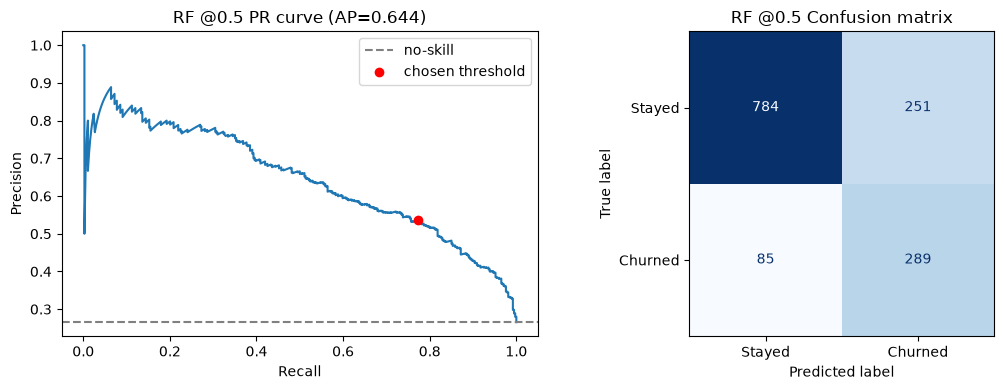


--- Tuned threshold ---
Classification report (threshold=0.309):
              precision    recall  f1-score   support

           0      0.938     0.583     0.719      1035
           1      0.436     0.893     0.586       374

    accuracy                          0.665      1409
   macro avg      0.687     0.738     0.652      1409
weighted avg      0.805     0.665     0.683      1409

PR-AUC: 0.6444 | ROC-AUC: 0.8397 | Flagged: 54.4%
Confusion matrix:
 [[603 432]
 [ 40 334]]


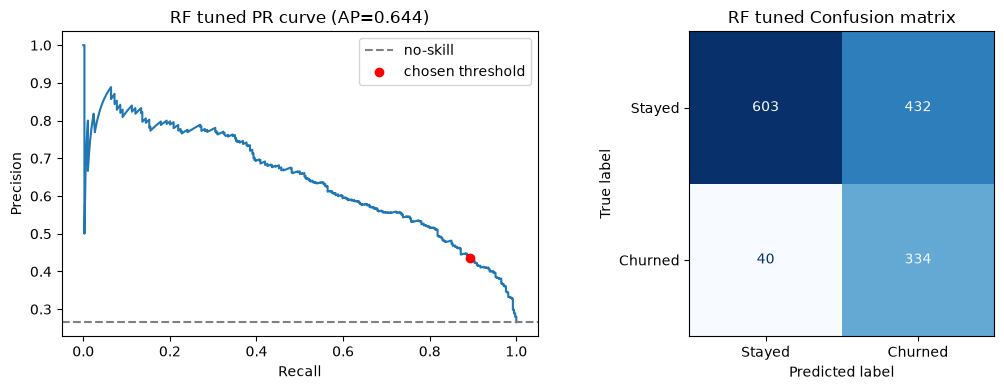

In [64]:

# 1. Baseline Random Forest inside the pipeline
rf_base = build_model(
    RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',   # handles the ~26% churn imbalance
        min_samples_leaf=5,        # limits overfitting from fully grown trees
        n_jobs=-1,
        random_state=42,
    )
)

# 2. Cross-validated PR-AUC on the TRAINING set
ap_scores = cross_val_score(rf_base, X_train, y_train, cv=cv, scoring='average_precision')
roc_scores = cross_val_score(rf_base, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"RF baseline CV PR-AUC : {ap_scores.mean():.4f} +/- {ap_scores.std():.4f}")
print(f"RF baseline CV ROC-AUC: {roc_scores.mean():.4f} +/- {roc_scores.std():.4f}")

# 3. Out-of-fold probabilities, used for threshold tuning (train set only)
oof_rf = cross_val_predict(rf_base, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
best_t, best_fb = pick_threshold(y_train, oof_rf)
print(f"\nBest threshold: {best_t:.3f} (F{BETA:g} = {best_fb:.3f})")
print(threshold_analysis(y_train, oof_rf, title='RF baseline'))

# 4. Fit on the full training set, then evaluate on the test set
rf_base.fit(X_train, y_train)
print("\n--- Default threshold 0.5 ---")
res_default = evaluate_model(rf_base, X_test, y_test, thresh=0.5, title='RF @0.5')
print("\n--- Tuned threshold ---")
res_tuned = evaluate_model(rf_base, X_test, y_test, thresh=best_t, title='RF tuned')

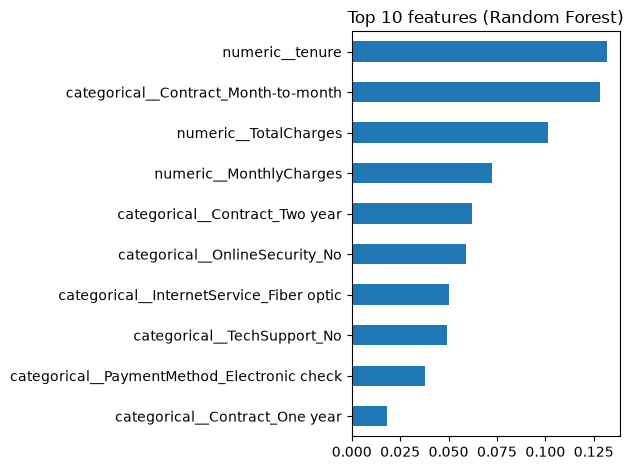

In [65]:
names = rf_base.named_steps['prep'].get_feature_names_out()
imp = pd.Series(rf_base.named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False)
imp.head(10).plot(kind='barh').invert_yaxis()
plt.title('Top 10 features (Random Forest)'); plt.tight_layout(); plt.show()


### 6.3 LightGBM

LGBM CV PR-AUC : 0.6537 +/- 0.0232
LGBM CV ROC-AUC: 0.8384 +/- 0.0110

Best threshold: 0.209 (F2 = 0.741)


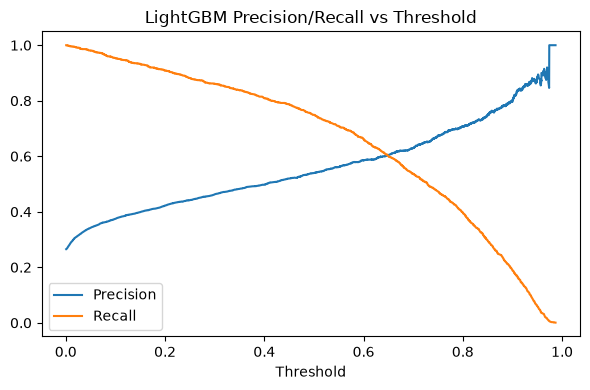

           precision  recall     F1     F2  flagged_%
threshold                                            
0.10           0.375   0.953  0.538  0.728     67.536
0.15           0.399   0.932  0.559  0.736     62.052
0.20           0.422   0.908  0.576  0.738     57.118
0.30           0.462   0.861  0.602  0.734     49.397
0.40           0.498   0.809  0.616  0.719     43.166
0.50           0.540   0.749  0.628  0.695     36.812
0.60           0.585   0.662  0.621  0.645     29.996
0.70           0.629   0.537  0.580  0.553     22.648

--- Default threshold 0.5 ---
Classification report (threshold=0.500):
              precision    recall  f1-score   support

           0      0.891     0.752     0.816      1035
           1      0.521     0.746     0.613       374

    accuracy                          0.750      1409
   macro avg      0.706     0.749     0.714      1409
weighted avg      0.793     0.750     0.762      1409

PR-AUC: 0.6472 | ROC-AUC: 0.8359 | Flagged: 38.0%
Confusion m

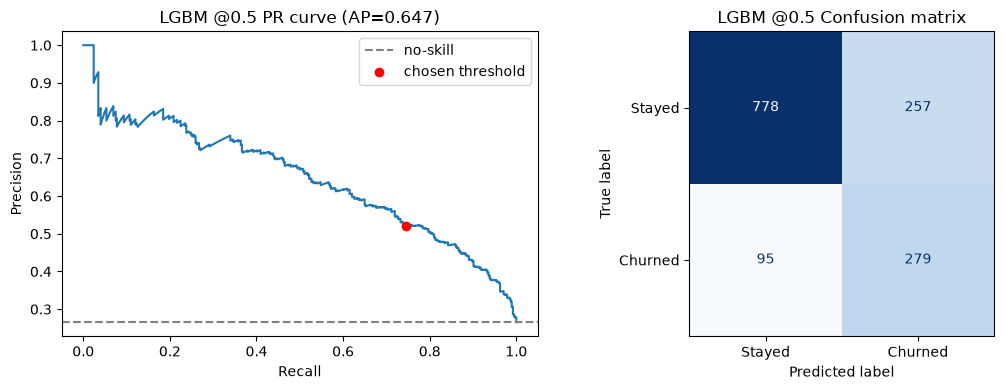


--- Tuned threshold ---
Classification report (threshold=0.209):
              precision    recall  f1-score   support

           0      0.939     0.554     0.697      1035
           1      0.422     0.901     0.575       374

    accuracy                          0.646      1409
   macro avg      0.681     0.727     0.636      1409
weighted avg      0.802     0.646     0.664      1409

PR-AUC: 0.6472 | ROC-AUC: 0.8359 | Flagged: 56.7%
Confusion matrix:
 [[573 462]
 [ 37 337]]


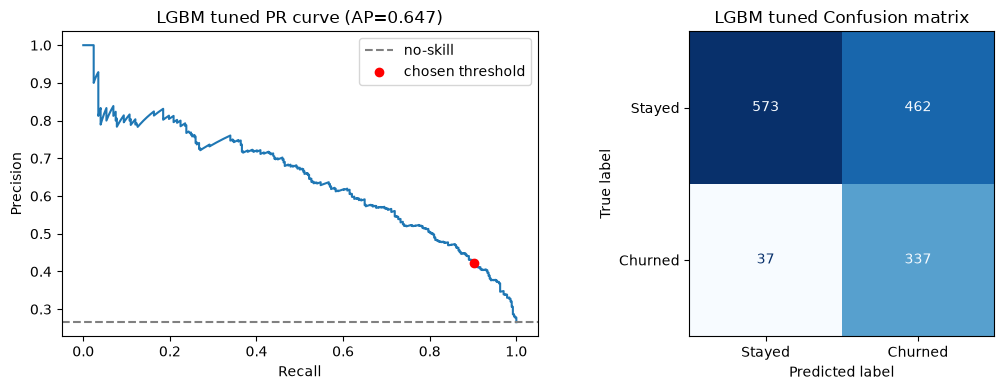

In [66]:
lgbm = build_model(
    LGBMClassifier(
        n_estimators=400,
        learning_rate=0.05,
        num_leaves=15,            # small trees: the Telco dataset is small (~5.6k train rows)
        min_child_samples=30,     # stops leaves from fitting tiny groups
        subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        class_weight='balanced',  # handles the ~26% churn imbalance
        random_state=42,
        n_jobs=-1,
        verbose=-1,               # silences LightGBM's log output
    )
)

# 1. Cross-validated scores on the TRAINING set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ap = cross_val_score(lgbm, X_train, y_train, cv=cv, scoring='average_precision')
roc = cross_val_score(lgbm, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"LGBM CV PR-AUC : {ap.mean():.4f} +/- {ap.std():.4f}")
print(f"LGBM CV ROC-AUC: {roc.mean():.4f} +/- {roc.std():.4f}")

# 2. Out-of-fold probabilities for threshold tuning (train set only)
oof_lgbm = cross_val_predict(lgbm, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
best_t_lgbm, best_fb = pick_threshold(y_train, oof_lgbm)
print(f"\nBest threshold: {best_t_lgbm:.3f} (F{BETA:g} = {best_fb:.3f})")
print(threshold_analysis(y_train, oof_lgbm, title='LightGBM'))

# 3. Fit on full training set, evaluate on test once per threshold
lgbm.fit(X_train, y_train)
print("\n--- Default threshold 0.5 ---")
res_lgbm_default = evaluate_model(lgbm, X_test, y_test, thresh=0.5, title='LGBM @0.5')
print("\n--- Tuned threshold ---")
res_lgbm_tuned = evaluate_model(lgbm, X_test, y_test, thresh=best_t_lgbm, title='LGBM tuned')


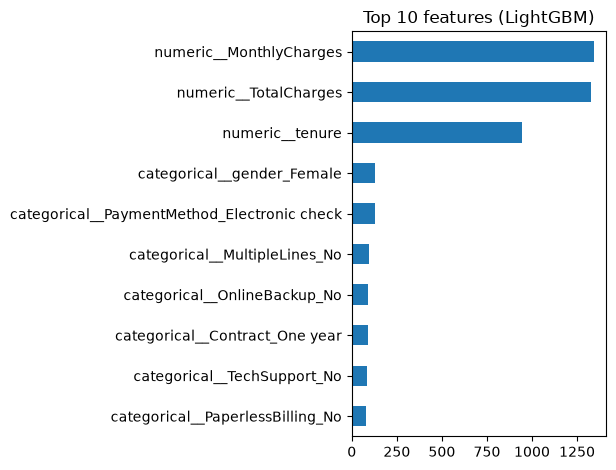

In [67]:
names = lgbm.named_steps['prep'].get_feature_names_out()
imp = pd.Series(lgbm.named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False)
imp.head(10).plot(kind='barh').invert_yaxis()
plt.title('Top 10 features (LightGBM)'); plt.tight_layout(); plt.show()

### 6.4 XGBoost

scale_pos_weight: 2.77
XGB CV PR-AUC : 0.6627 +/- 0.0199
XGB CV ROC-AUC: 0.8443 +/- 0.0112

Best threshold: 0.290 (F2 = 0.746)


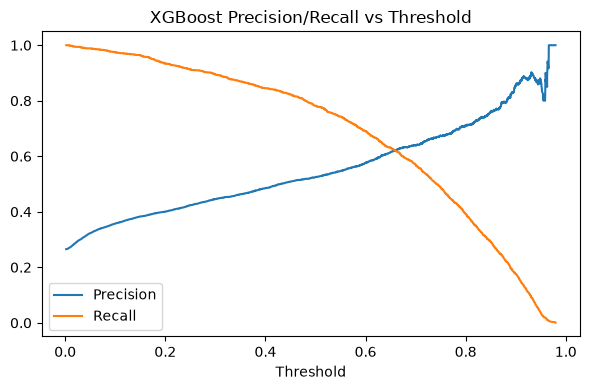

           precision  recall     F1     F2  flagged_%
threshold                                            
0.10           0.357   0.975  0.523  0.724     72.417
0.15           0.383   0.964  0.548  0.740     66.755
0.20           0.400   0.934  0.560  0.737     61.892
0.30           0.446   0.894  0.595  0.744     53.248
0.40           0.485   0.845  0.616  0.736     46.219
0.50           0.525   0.782  0.628  0.712     39.528
0.60           0.577   0.690  0.628  0.664     31.771
0.70           0.639   0.569  0.602  0.582     23.642

--- Default threshold 0.5 ---
Classification report (threshold=0.500):
              precision    recall  f1-score   support

           0      0.906     0.733     0.810      1035
           1      0.517     0.789     0.624       374

    accuracy                          0.748      1409
   macro avg      0.711     0.761     0.717      1409
weighted avg      0.802     0.748     0.761      1409

PR-AUC: 0.6553 | ROC-AUC: 0.8417 | Flagged: 40.5%
Confusion m

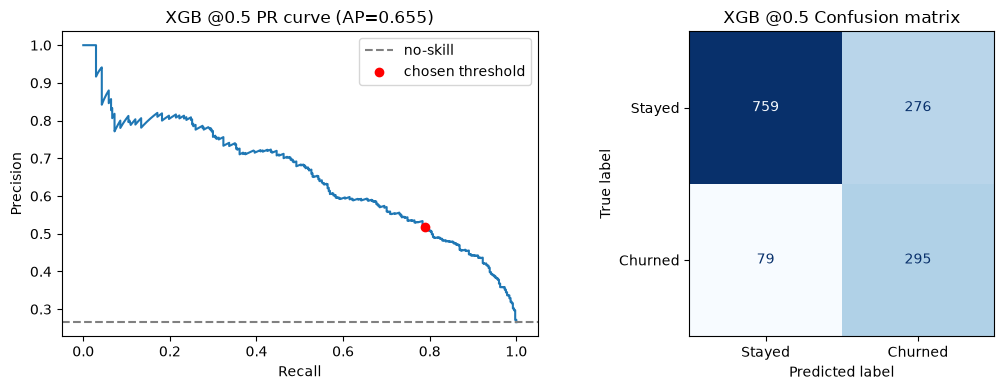


--- Tuned threshold ---
Classification report (threshold=0.290):
              precision    recall  f1-score   support

           0      0.944     0.588     0.725      1035
           1      0.442     0.904     0.594       374

    accuracy                          0.672      1409
   macro avg      0.693     0.746     0.660      1409
weighted avg      0.811     0.672     0.690      1409

PR-AUC: 0.6553 | ROC-AUC: 0.8417 | Flagged: 54.2%
Confusion matrix:
 [[609 426]
 [ 36 338]]


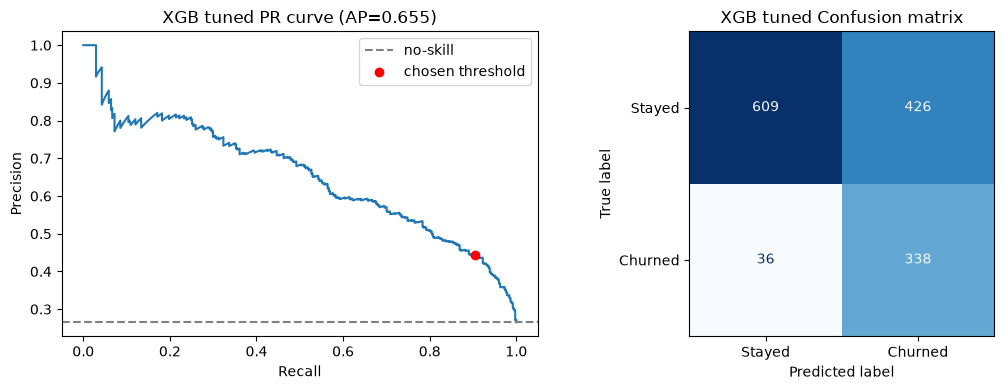

In [68]:
# scale_pos_weight = (# stayed) / (# churned) in the TRAINING set, handles the ~26% churn imbalance
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight: {spw:.2f}")

xgb = build_model(
    XGBClassifier(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=3,               # shallow trees: Telco is small (~5.6k train rows)
        min_child_weight=5,        # stops leaves from fitting tiny groups
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        scale_pos_weight=spw,
        eval_metric='aucpr',
        tree_method='hist',
        random_state=42,
        n_jobs=-1,
    )
)

# 1. Cross-validated scores on the TRAINING set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ap_xgb = cross_val_score(xgb, X_train, y_train, cv=cv, scoring='average_precision')
roc_xgb = cross_val_score(xgb, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"XGB CV PR-AUC : {ap_xgb.mean():.4f} +/- {ap_xgb.std():.4f}")
print(f"XGB CV ROC-AUC: {roc_xgb.mean():.4f} +/- {roc_xgb.std():.4f}")

# 2. Out-of-fold probabilities for threshold tuning (train set only)
oof_xgb = cross_val_predict(xgb, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
best_t_xgb, best_fb = pick_threshold(y_train, oof_xgb)
print(f"\nBest threshold: {best_t_xgb:.3f} (F{BETA:g} = {best_fb:.3f})")
print(threshold_analysis(y_train, oof_xgb, title='XGBoost'))

# 3. Fit on full training set, evaluate on test once per threshold
xgb.fit(X_train, y_train)
print("\n--- Default threshold 0.5 ---")
res_xgb_default = evaluate_model(xgb, X_test, y_test, thresh=0.5, title='XGB @0.5')
print("\n--- Tuned threshold ---")
res_xgb_tuned = evaluate_model(xgb, X_test, y_test, thresh=best_t_xgb, title='XGB tuned')


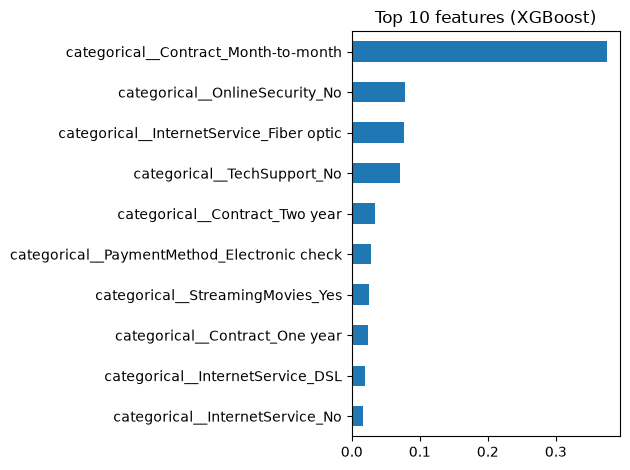

In [69]:
names = xgb.named_steps['prep'].get_feature_names_out()
imp = pd.Series(xgb.named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False)
imp.head(10).plot(kind='barh').invert_yaxis()
plt.title('Top 10 features (XGBoost)'); plt.tight_layout(); plt.show()

### 6.5 Model comparison
Models are compared by cross-validated PR-AUC on the training set. The test set is shown only as a final check.

                     CV PR-AUC  CV PR-AUC std  CV ROC-AUC  Test PR-AUC  \
XGBoost                 0.6627         0.0199      0.8443       0.6553   
Logistic Regression     0.6600         0.0195      0.8459       0.6326   
Random Forest           0.6548         0.0238      0.8453       0.6444   
LightGBM                0.6537         0.0232      0.8384       0.6472   

                     Test ROC-AUC  
XGBoost                    0.8417  
Logistic Regression        0.8413  
Random Forest              0.8397  
LightGBM                   0.8359  


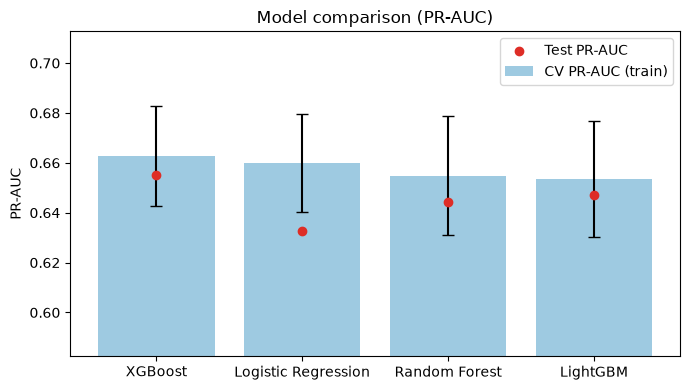

In [70]:
cv_scores = {
    'Logistic Regression': (ap_lr, roc_lr),
    'Random Forest': (ap_scores, roc_scores),   # from your RF cell
    'LightGBM':      (ap,        roc),          # from your LightGBM cell
    'XGBoost':       (ap_xgb,    roc_xgb),      # from your XGBoost cell
}
test_res = {
    'Logistic Regression': res_lr_default,
    'Random Forest': res_default,        # evaluate_model result for RF
    'LightGBM':      res_lgbm_default,
    'XGBoost':       res_xgb_default,
}

comparison = pd.DataFrame({
    name: {
        'CV PR-AUC':     cv_scores[name][0].mean(),
        'CV PR-AUC std': cv_scores[name][0].std(),
        'CV ROC-AUC':    cv_scores[name][1].mean(),
        'Test PR-AUC':   test_res[name]['ap'],
        'Test ROC-AUC':  test_res[name]['roc'],
    } for name in cv_scores
}).T.sort_values('CV PR-AUC', ascending=False)
print(comparison.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(comparison))
ax.bar(x, comparison['CV PR-AUC'], yerr=comparison['CV PR-AUC std'],
       capsize=4, color='#9ecae1', label='CV PR-AUC (train)')
ax.scatter(x, comparison['Test PR-AUC'], color='#de2d26', zorder=3, label='Test PR-AUC')
ax.set_xticks(x); ax.set_xticklabels(comparison.index)
vals = comparison[['CV PR-AUC', 'Test PR-AUC']]
ax.set_ylim(vals.min().min() - 0.05, vals.max().max() + 0.05)
ax.set_ylabel('PR-AUC'); ax.set_title('Model comparison (PR-AUC)')
ax.legend(); plt.tight_layout(); plt.show()

In [71]:
for name, m in [('LogReg', logreg), ('RF', rf_base), ('LGBM', lgbm), ('XGB', xgb)]:
    t0 = time.time(); m.fit(X_train, y_train)
    print(f"{name}: {time.time() - t0:.2f}s")


LogReg: 0.08s
RF: 0.82s
LGBM: 0.28s
XGB: 0.27s


### 6.6 Feature engineering experiment
Two row-wise features: a tenure group and a count of add-on services. They use no fitted statistics, so they are safe to create after the split. Each model is compared with and without them on the same CV folds.

In [72]:
ADDON_COLS = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

def add_features(data):
    """Row-wise features (no fitted statistics, so no leakage)."""
    data = data.copy()
    data['tenure_group'] = pd.cut(data['tenure'], bins=[-1, 12, 24, 48, 72],
                                  labels=['0-12', '13-24', '25-48', '49-72']).astype(str)
    data['n_addons'] = (data[ADDON_COLS] == 'Yes').sum(axis=1)
    return data

def make_preprocessor(X):
    """Same preprocessing as before, but built from whatever columns X has."""
    num = X.select_dtypes(include=np.number).columns.tolist()
    cat = X.select_dtypes(exclude=np.number).columns.tolist()
    return ColumnTransformer([
        ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num),
        ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                                  ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat),
    ])

X_train_fe, X_test_fe = add_features(X_train), add_features(X_test)

rows = {}
for model_name, base_clf in [('Logistic Regression', logreg.named_steps['clf']),
                             ('XGBoost (baseline params)', xgb.named_steps['clf'])]:
    for label, Xtr in [('original features', X_train), ('+ engineered features', X_train_fe)]:
        model = Pipeline([('prep', make_preprocessor(Xtr)), ('clf', clone(base_clf))])
        s = cross_val_score(model, Xtr, y_train, cv=cv, scoring='average_precision')
        rows[(model_name, label)] = {'CV PR-AUC': s.mean(), 'CV PR-AUC std': s.std()}

fe_table = pd.DataFrame(rows).T.round(4)
fe_table

CV PR-AUC  CV PR-AUC std
Logistic Regression       original features         0.6600         0.0195
                          + engineered features     0.6641         0.0132
XGBoost (baseline params) original features         0.6627         0.0199
                          + engineered features     0.6627         0.0196

**Result:**  The engineered features did not provide a meaningful improvement for XGBoost. Its CV PR-AUC remained at 0.6627, while the standard deviation changed only slightly from 0.0199 to 0.0196. For Logistic Regression, CV PR-AUC increased from 0.6600 to 0.6641 (+0.0041), while the standard deviation decreased from 0.0195 to 0.0132. This improvement is small relative to the fold-to-fold variability, so the engineered features were not retained in the final model. Keeping the original features also simplifies the pipeline.

**Model choice going into tuning: XGBoost.** All four models performed within noise of each other (CV PR-AUC 0.654 to 0.663, std ~0.02), including the logistic regression baseline (0.660). XGBoost was chosen for the highest CV PR-AUC and because gradient boosting has more tunable hyperparameters. Logistic regression scoring this close is a useful finding: a simple, interpretable linear model is almost as good under cross-validation. Its lower test PR-AUC (0.633) is likely split noise, since the test set has only 374 churners, and selection is based on CV, not the test set.

# 7. Hyperparameter Tuning (Optuna)

In [37]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
spw = (y_train == 0).sum() / (y_train == 1).sum()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    params = {
        "n_estimators":     trial.suggest_int("n_estimators", 200, 600),
        "learning_rate":    trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "max_depth":        trial.suggest_int("max_depth", 2, 6),
        "subsample":        trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma":            trial.suggest_float("gamma", 0, 5),
        "reg_alpha":        trial.suggest_float("reg_alpha", 1e-3, 5, log=True),
        "reg_lambda":       trial.suggest_float("reg_lambda", 0.5, 10, log=True),
        "scale_pos_weight": spw,
        "tree_method":      "hist",
        "random_state":     42,
        "n_jobs":           -1,
    }
    model = build_model(XGBClassifier(**params))
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="average_precision")
    return scores.mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=50)

print("Best CV PR-AUC:", round(study.best_value, 4))
print(study.best_params)


Best CV PR-AUC: 0.6722
{'n_estimators': 477, 'learning_rate': 0.03077718570613165, 'max_depth': 2, 'subsample': 0.8550556880861993, 'colsample_bytree': 0.5456068475260045, 'min_child_weight': 4, 'gamma': 4.298660550423297, 'reg_alpha': 1.4011816332902207, 'reg_lambda': 7.165670373373003}


# 8. Final Tuned Model
The threshold is chosen on out-of-fold training predictions only. The test set is evaluated once per threshold, for reporting.

Tuned threshold: 0.368 (F2 = 0.752)


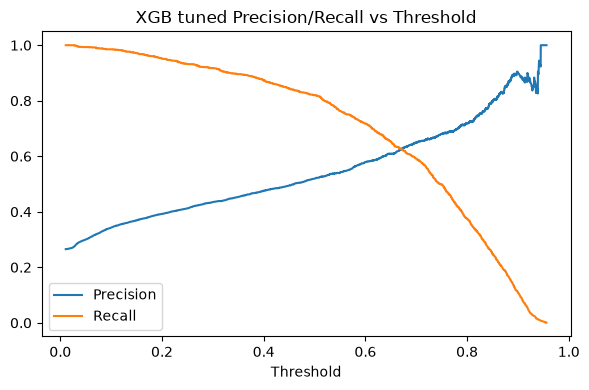

           precision  recall     F1     F2  flagged_%
threshold                                            
0.10           0.343   0.985  0.509  0.717     76.269
0.15           0.369   0.971  0.535  0.732     69.844
0.20           0.392   0.952  0.556  0.741     64.377
0.30           0.435   0.917  0.590  0.751     55.946
0.40           0.476   0.874  0.616  0.749     48.704
0.50           0.519   0.820  0.636  0.735     41.889
0.60           0.579   0.717  0.641  0.684     32.872
0.70           0.648   0.591  0.618  0.601     24.175
Training time: 0.19s | Prediction time: 0.0180s (0.013 ms/customer)

--- Default threshold 0.5 ---
Classification report (threshold=0.500):
              precision    recall  f1-score   support

           0      0.908     0.717     0.801      1035
           1      0.505     0.799     0.619       374

    accuracy                          0.739      1409
   macro avg      0.707     0.758     0.710      1409
weighted avg      0.801     0.739     0.753     

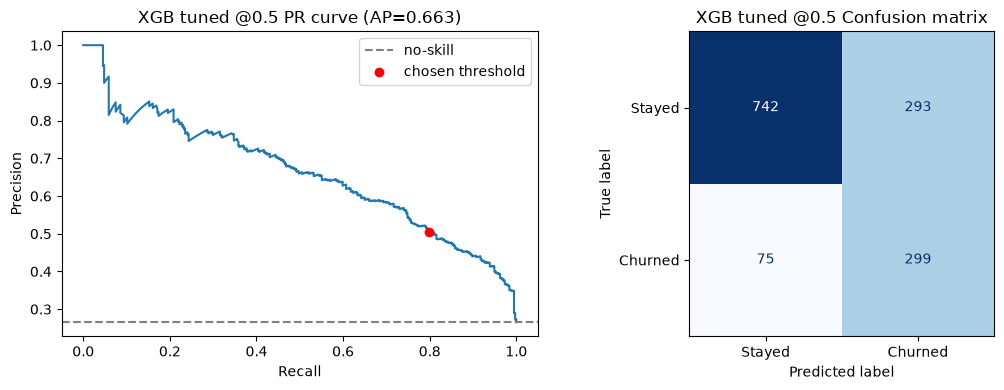


--- Tuned threshold ---
Classification report (threshold=0.368):
              precision    recall  f1-score   support

           0      0.931     0.623     0.747      1035
           1      0.455     0.872     0.598       374

    accuracy                          0.689      1409
   macro avg      0.693     0.747     0.672      1409
weighted avg      0.805     0.689     0.707      1409

PR-AUC: 0.6632 | ROC-AUC: 0.8470 | Flagged: 50.8%
Confusion matrix:
 [[645 390]
 [ 48 326]]


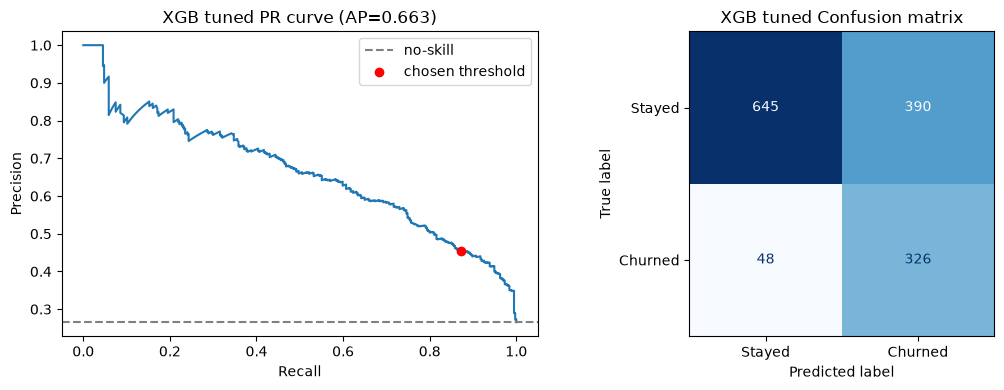

              CV PR-AUC  Test PR-AUC  Gain (CV)
Baseline XGB     0.6627       0.6553    -0.0000
Tuned XGB        0.6722       0.6632     0.0095

At threshold 0.368: catches 87.2% of churners by contacting 50.8% of customers (precision 45.5%)


In [38]:
# ── 1. Build the tuned model through the pipeline ─────────────────────────────
spw = (y_train == 0).sum() / (y_train == 1).sum()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best_xgb = build_model(XGBClassifier(
    **study.best_params,          # must come from the CV-based Optuna search
    scale_pos_weight=spw,
    tree_method='hist',
    random_state=42,
    n_jobs=-1,
))

# ── 2. Threshold from out-of-fold predictions on TRAIN only ───────────────────
oof = cross_val_predict(best_xgb, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
best_t, best_fb = pick_threshold(y_train, oof)
print(f"Tuned threshold: {best_t:.3f} (F{BETA:g} = {best_fb:.3f})")
print(threshold_analysis(y_train, oof, title='XGB tuned'))

# ── 3. Fit on full train, with timing ─────────────────────────────────────────
t0 = time.perf_counter()
best_xgb.fit(X_train, y_train)
train_time = time.perf_counter() - t0

# ── 4. Prediction timing ──────────────────────────────────────────────────────
t0 = time.perf_counter()
_ = best_xgb.predict_proba(X_test)
pred_time = time.perf_counter() - t0
print(f"Training time: {train_time:.2f}s | Prediction time: {pred_time:.4f}s "
      f"({pred_time / len(X_test) * 1000:.3f} ms/customer)")

# ── 5. Final test evaluation (once per threshold, report only) ────────────────
print("\n--- Default threshold 0.5 ---")
res_xgb_final_default = evaluate_model(best_xgb, X_test, y_test, thresh=0.5, title='XGB tuned @0.5')
print("\n--- Tuned threshold ---")
res_xgb_final = evaluate_model(best_xgb, X_test, y_test, thresh=best_t, title='XGB tuned')

# ── 6. Before vs after tuning ─────────────────────────────────────────────────
baseline_cv_ap = ap_xgb.mean()          # baseline XGB CV PR-AUC (0.6627)
baseline_test_ap = res_xgb_default['ap']  # baseline XGB test PR-AUC (0.6553)

summary = pd.DataFrame({
    'Baseline XGB': {'CV PR-AUC': baseline_cv_ap,
                     'Test PR-AUC': baseline_test_ap},
    'Tuned XGB':    {'CV PR-AUC': study.best_value,
                     'Test PR-AUC': res_xgb_final['ap']},
}).T.round(4)
summary['Gain (CV)'] = (summary['CV PR-AUC'] - baseline_cv_ap).round(4)
print(summary)

# ── 7. Business view at the tuned threshold ───────────────────────────────────
tn, fp, fn, tp = res_xgb_final['cm'].ravel()
print(f"\nAt threshold {best_t:.3f}: catches {tp / (tp + fn) * 100:.1f}% of churners "
      f"by contacting {(tp + fp) / len(y_test) * 100:.1f}% of customers "
      f"(precision {tp / (tp + fp) * 100:.1f}%)")


# 9. Model Interpretation (SHAP)
Which features drive the churn predictions, and in which direction?

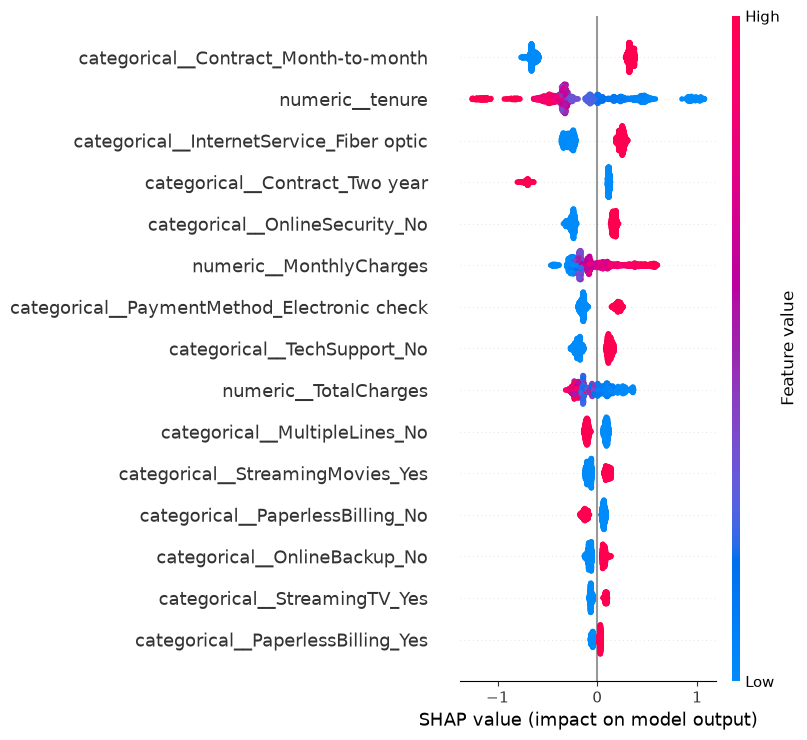

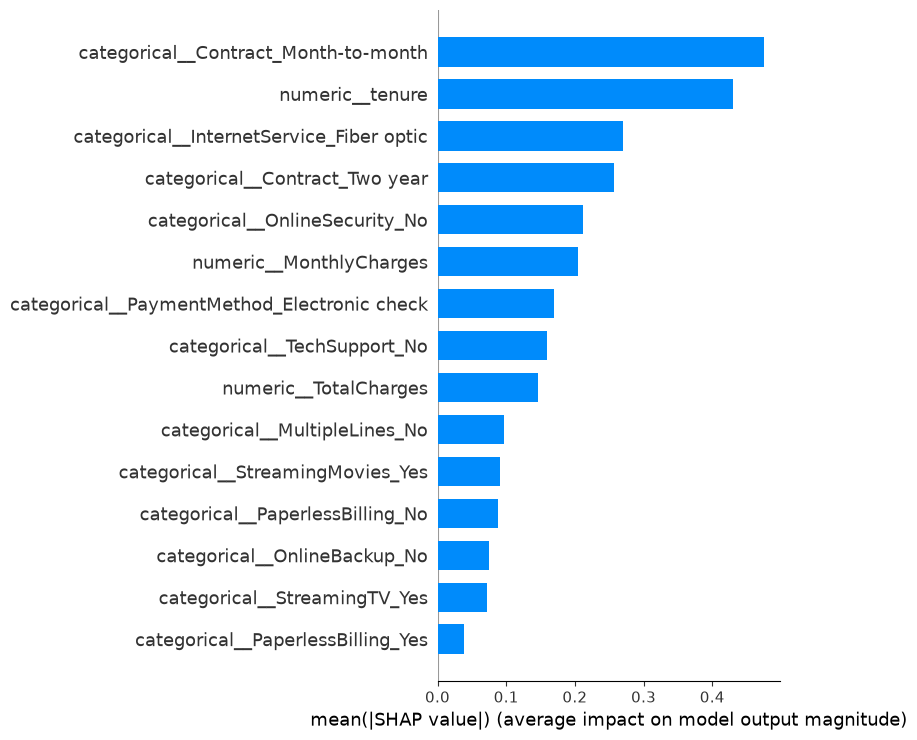

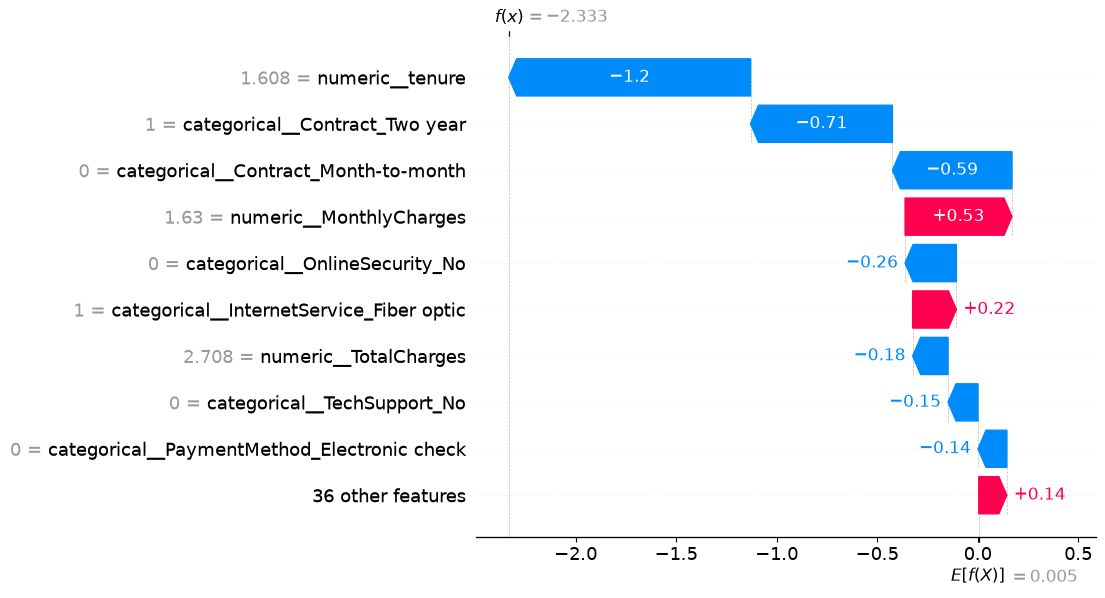

In [39]:
prep = best_xgb.named_steps['prep']
clf  = best_xgb.named_steps['clf']

# Transform the test set with the fitted preprocessor (dense, with feature names)
X_te_t = prep.transform(X_test)
if sp.issparse(X_te_t):
    X_te_t = X_te_t.toarray()
names = prep.get_feature_names_out()
X_te_df = pd.DataFrame(X_te_t, columns=names)

explainer = shap.TreeExplainer(clf)
sv = explainer(X_te_df)             # Explanation object

# 1. Global view: which features matter and in which direction
shap.summary_plot(sv.values, X_te_df, max_display=15)

# 2. Simple ranking by average impact
shap.summary_plot(sv.values, X_te_df, plot_type='bar', max_display=15)

# 3. One customer: why was this person flagged?
shap.plots.waterfall(sv[0])


### SHAP findings

- **Contract type is the strongest driver.** Month-to-month contracts push predictions strongly toward churn, while two-year contracts push them toward staying.
- **Short tenure raises risk.** Low tenure pushes predictions toward churn and high tenure toward staying, so new customers are the highest-risk group.
- **Higher-risk service profile.** Fiber optic internet, no online security, no tech support, electronic check payment, and higher monthly charges all push predictions toward churn.

*Note: SHAP values are in log-odds, and they show what the model relies on, not what causes churn. Correlated features (such as tenure and total charges) share credit, so the exact ordering should not be over-read.*

# 10. Conclusion

**Results**
- Dataset: 7,043 customers, about 26.5% churn. Four models were compared by 5-fold CV PR-AUC: XGBoost 0.663, Logistic Regression 0.660, Random Forest 0.655 and LightGBM 0.654 (std ~0.02). They are within noise of each other, so a simple linear model is nearly as good as the boosted trees.
- Engineered features (tenure group, add-on count) gave no gain beyond noise and were not used in the final model.
- XGBoost was tuned with Optuna on CV PR-AUC. CV PR-AUC improved from 0.6627 to 0.6722 (+0.0095, a small gain within noise), and test PR-AUC from 0.6553 to 0.6632 (ROC-AUC 0.8470).
- Threshold choices on the test set:
  - F2-tuned (0.368): catches **87.2% of churners** by contacting **50.8% of customers** (precision 45.5%).
  - Default 0.5: catches 79.9% of churners by contacting 42.0% of customers (precision 50.5%).

**Business takeaway**
Retention efforts should focus on new, month-to-month customers on fiber optic plans, especially those without online security or tech support, with higher monthly charges, and those paying by electronic check.

